Given an integer array nums and an integer k, return true if nums has a good subarray or false otherwise.

A good subarray is a subarray where:

its length is at least two, and
the sum of the elements of the subarray is a multiple of k.
Note that:

A subarray is a contiguous part of the array.
An integer x is a multiple of k if there exists an integer n such that x = n * k. 0 is always a multiple of k.


Example 1:

Input: nums = [23,2,4,6,7], k = 6
Output: true
Explanation: [2, 4] is a continuous subarray of size 2 whose elements sum up to 6.
Example 2:

Input: nums = [23,2,6,4,7], k = 6
Output: true
Explanation: [23, 2, 6, 4, 7] is an continuous subarray of size 5 whose elements sum up to 42.
42 is a multiple of 6 because 42 = 7 * 6 and 7 is an integer.
Example 3:

Input: nums = [23,2,6,4,7], k = 13
Output: false


Constraints:

1 <= nums.length <= 105
0 <= nums[i] <= 109
0 <= sum(nums[i]) <= 231 - 1
1 <= k <= 231 - 1

In [ ]:
fun checkSubarraySum(nums: IntArray, k: Int): Boolean {
    val hashMap = HashMap<Int, Int>()
    var remains = 0
    var cur = 0
    var zero = 0
    var res = 0

    nums.forEach {
        remains = (remains + it) % k
    }


    hashMap.put(0, -1)
    for (i in nums.indices) {

        if (nums[i] == 0){
            zero++
        }
        else {
            if (zero>1) return true
            zero = 0
        }

        hashMap.put(cur , i)
        cur = (cur + nums[i]) % k

        val needed = (cur - remains + k) % k

        res = min(res, i - hashMap.getOrDefault(needed, (-nums.size) * 2))
    }

    return res < nums.size
}

In [ ]:
fun checkSubarraySum(nums: IntArray, k: Int): Boolean {
    val hashMap = HashMap<Int, Int>()
    var cur = 0

    hashMap.put(0, -1)

    for (i in nums.indices) {
        cur = (cur + nums[i]) % k

        val prev = hashMap.get(cur)

        if ( prev != null) {
            if (i - prev > 1) return true
        }
        else
            hashMap.put(cur, i)
    }

    return false
}

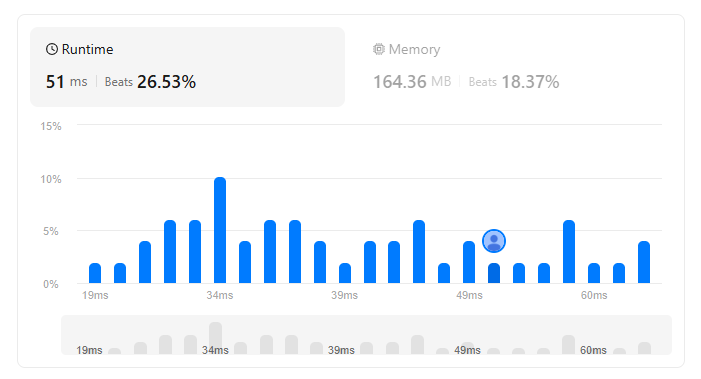
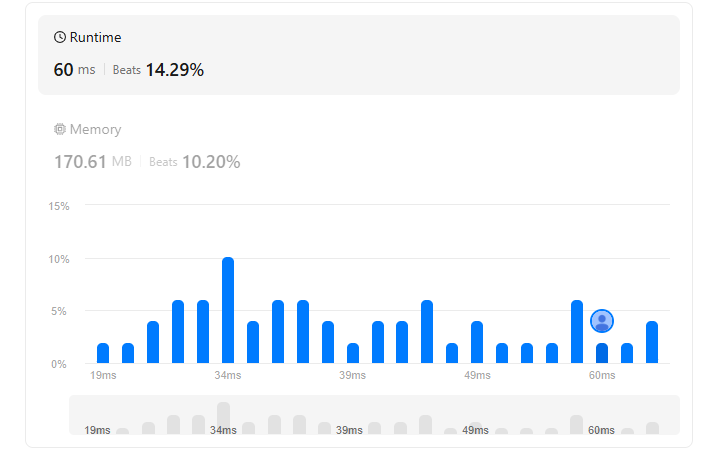